# TradeKriya: 5-Year Structural Personality & Safety Profiling Engine

### Quantitative Problem Statement
In real-world trading, different stocks exhibit drastically different behavioral regimes across Demand and Supply zones:
1. **Falling-Zone Risk (Cascade Breakdowns)**: Stocks in secular downtrends or capital-destructive phases that continuously shatter demand zones. Buying the dip on these stocks turns into a "falling knife" trap.
2. **Expansion Runners (Supply Breakers)**: High-momentum compounders that rarely respect overhead resistance and break out to new highs more often than mean-reverting.
3. **Mean-Reversion Oscillators**: Clean, cyclical range-bound stocks that reliably bounce off support and reject resistance.
4. **Safe D&S Anchors**: Institutional favorites with high support integrity, low tail drawdowns, and high bounce probability upon entering demand.

This notebook evaluates every stock over **5 years (~1,270 trading sessions)** across **6 quantitative parameters** to classify their behavioral DNA and label them with a **Safety Score (0 to 100)**.


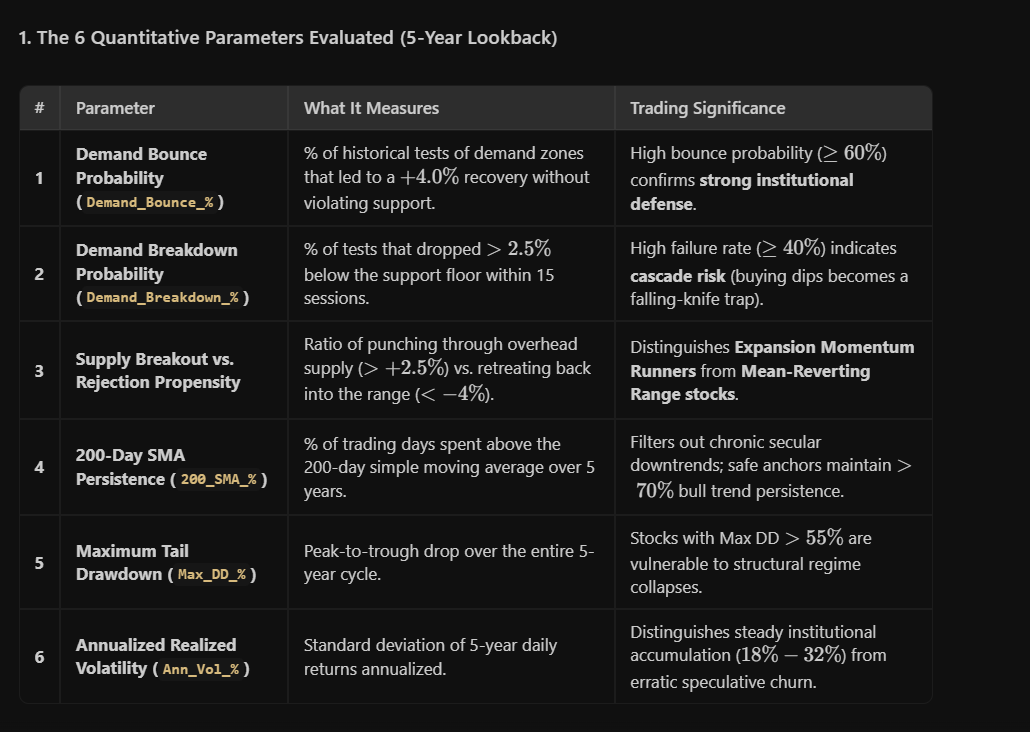

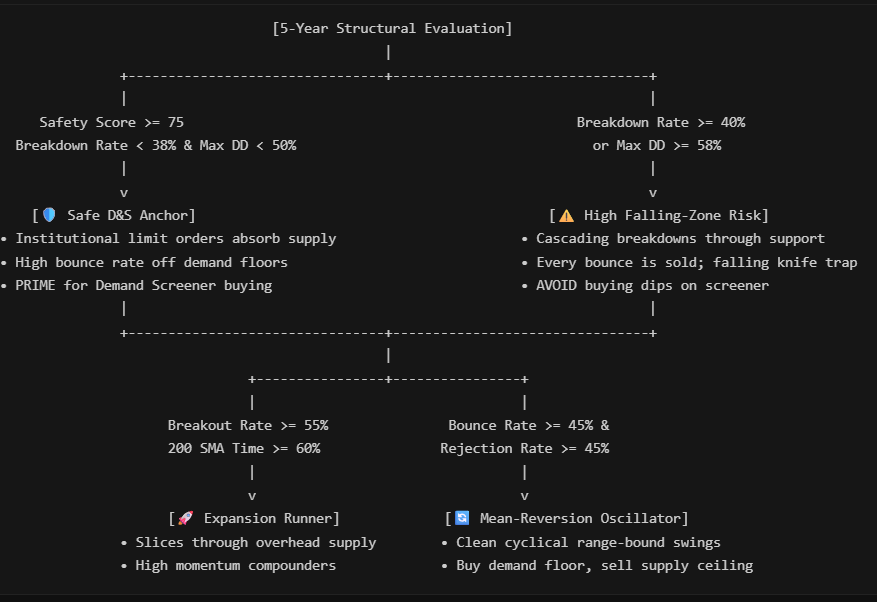

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from datetime import datetime

# Set institutional dark theme styling
plt.style.use('dark_background')
plt.rcParams['font.sans-serif'] = 'Segoe UI', 'DejaVu Sans', 'Helvetica'
plt.rcParams['axes.edgecolor'] = '#30363d'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.color'] = '#21262d'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.6

DATA_PATH = 'screener/data/fo_historical_dump.json'
with open(DATA_PATH, 'r') as f:
    raw_dump = json.load(f)

print(f"Loaded {len(raw_dump)} tickers from {DATA_PATH}")


Loaded 115 tickers from screener/data/fo_historical_dump.json


In [2]:
def parse_df(records):
    """Converts raw records to sorted DataFrame."""
    df = pd.DataFrame(records, columns=['date', 'open', 'high', 'low', 'close', 'volume'])
    df['date'] = pd.to_datetime(df['date'].astype(str).str.slice(0, 10))
    df = df.sort_values('date').reset_index(drop=True)
    for c in ['open', 'high', 'low', 'close', 'volume']:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    return df

universe_dfs = {}
for sym, records in raw_dump.items():
    if len(records) >= 300:
        universe_dfs[sym] = parse_df(records)

print(f"Ingested {len(universe_dfs)} stocks with long multi-year history.")
sample_sym = 'BHARTIARTL'
print(f"Sample Stock ({sample_sym}): {len(universe_dfs[sample_sym])} bars from {universe_dfs[sample_sym]['date'].iloc[0].strftime('%Y-%m-%d')} to {universe_dfs[sample_sym]['date'].iloc[-1].strftime('%Y-%m-%d')}")


Ingested 115 stocks with long multi-year history.
Sample Stock (BHARTIARTL): 1279 bars from 2021-08-23 to 2026-10-16


In [3]:
def compute_5y_structural_profile(symbol, df):
    """
    Evaluates 6 core quantitative dimensions over trailing 5 years:
    1. Demand Bounce Probability (Support Integrity)
    2. Demand Breakdown Probability (Falling Zone Cascade Risk)
    3. Supply Breakout vs Rejection Propensity
    4. 200-Day SMA Bullish Persistence (% of trading days above 200 SMA)
    5. Maximum Tail Drawdown (Max DD)
    6. Annualized Realized Volatility
    """
    df = df.copy()
    
    # ATR & Trend Indicators
    tr = pd.concat([
        df['high'] - df['low'],
        (df['high'] - df['close'].shift(1)).abs(),
        (df['low'] - df['close'].shift(1)).abs()
    ], axis=1).max(axis=1)
    df['atr'] = tr.ewm(alpha=1/14, min_periods=14, adjust=False).mean()
    df['sma_200'] = df['close'].rolling(200).mean()
    
    # 1. 200-Day SMA Bullish Persistence
    valid_sma = df.dropna(subset=['sma_200'])
    pct_above_200 = float((valid_sma['close'] > valid_sma['sma_200']).mean() * 100.0) if len(valid_sma) > 0 else 50.0
    
    # 2. Maximum Tail Drawdown
    peak = df['close'].cummax()
    dd = (df['close'] - peak) / peak
    max_dd = float(abs(dd.min() * 100.0))
    
    # 3. Realized Annualized Volatility
    pct_rets = df['close'].pct_change().dropna()
    ann_vol = float(pct_rets.std() * np.sqrt(252) * 100.0)
    
    # 4. Vectorized Local Pivot Detection (5-bar window)
    lows = df['low'].values
    highs = df['high'].values
    
    is_pivot_low = (lows[2:-2] < lows[1:-3]) & (lows[2:-2] < lows[:-4]) & (lows[2:-2] < lows[3:-1]) & (lows[2:-2] < lows[4:])
    pivot_low_indices = np.where(is_pivot_low)[0] + 2
    
    is_pivot_high = (highs[2:-2] > highs[1:-3]) & (highs[2:-2] > highs[:-4]) & (highs[2:-2] > highs[3:-1]) & (highs[2:-2] > highs[4:])
    pivot_high_indices = np.where(is_pivot_high)[0] + 2
    
    # Evaluate Historical Demand Tests (Forward 15-session outcomes)
    bounces = 0
    breakdowns = 0
    d_tests = 0
    for idx in pivot_low_indices[:-1]:
        p_low = lows[idx]
        fwd_low = lows[idx+1 : min(len(df), idx+15)]
        fwd_high = highs[idx+1 : min(len(df), idx+15)]
        if len(fwd_low) == 0: continue
        d_tests += 1
        # Breakdown: Slices more than 2.5% below pivot floor
        if np.min(fwd_low) < p_low * 0.975:
            breakdowns += 1
        # Bounce: Stages a +4.0% recovery off pivot floor
        elif np.max(fwd_high) > p_low * 1.04:
            bounces += 1
            
    demand_bounce_rate = (bounces / d_tests * 100.0) if d_tests > 0 else 50.0
    demand_breakdown_rate = (breakdowns / d_tests * 100.0) if d_tests > 0 else 50.0
    
    # Evaluate Historical Supply Tests
    breakouts = 0
    rejections = 0
    s_tests = 0
    for idx in pivot_high_indices[:-1]:
        p_high = highs[idx]
        fwd_high = highs[idx+1 : min(len(df), idx+15)]
        fwd_low = lows[idx+1 : min(len(df), idx+15)]
        if len(fwd_high) == 0: continue
        s_tests += 1
        # Breakout: Clears more than 2.5% above pivot ceiling
        if np.max(fwd_high) > p_high * 1.025:
            breakouts += 1
        # Rejection: Drops more than 4.0% off ceiling
        elif np.min(fwd_low) < p_high * 0.96:
            rejections += 1
            
    supply_breakout_rate = (breakouts / s_tests * 100.0) if s_tests > 0 else 50.0
    supply_rejection_rate = (rejections / s_tests * 100.0) if s_tests > 0 else 50.0

    # 5. Safety Score Calibration (0 to 100)
    score = 0
    score += min(30, (demand_bounce_rate / 60.0) * 30)                  # Support bounce ability (up to 30 pts)
    score += max(0, min(20, (1.0 - (demand_breakdown_rate - 20) / 40.0) * 20)) # Low breakdown risk (up to 20 pts)
    score += max(0, min(20, (1.0 - (max_dd - 20) / 40.0) * 20))        # Tail risk control (up to 20 pts)
    score += min(15, (pct_above_200 / 70.0) * 15)                       # Macro bull trend (up to 15 pts)
    score += 15 if (18 <= ann_vol <= 32) else (10 if ann_vol < 18 else max(0, 15 - (ann_vol - 32)*0.5)) # Volatility (up to 15 pts)
    
    safety_score = round(min(100.0, max(0.0, score)), 1)
    
    # 6. Structural Behavioral Classification
    if demand_breakdown_rate >= 42.0 or max_dd >= 58.0:
        label = "High Falling-Zone Risk"
        recommendation = "AVOID Buying Dips (Cascade traps; demand levels fail repeatedly)"
    elif supply_breakout_rate >= 45.0 and pct_above_200 >= 60.0:
        label = "Expansion Runner"
        recommendation = "Breakout Favored (Regularly punches through overhead supply)"
    elif safety_score >= 75.0 and demand_breakdown_rate < 38.0 and max_dd < 50.0:
        label = "Safe D&S Anchor"
        recommendation = "Safe for Demand-Buying (Institutional limit orders consistently absorb supply)"
    elif demand_bounce_rate >= 45.0 and supply_rejection_rate >= 45.0:
        label = "Mean-Reversion Oscillating"
        recommendation = "Range-Bound Setup (Reliable for buying floor and selling ceiling)"
    else:
        label = "Moderate Integrity / Transitional"
        recommendation = "Requires Stricter Volume Confirmation"
        
    return {
        'Symbol': symbol,
        'History_Years': round(len(df) / 250, 1),
        'Safety_Score': safety_score,
        'Structural_Label': label,
        'Demand_Bounce_%': round(demand_bounce_rate, 1),
        'Demand_Breakdown_%': round(demand_breakdown_rate, 1),
        'Supply_Breakout_%': round(supply_breakout_rate, 1),
        'Supply_Rejection_%': round(supply_rejection_rate, 1),
        '200_SMA_%': round(pct_above_200, 1),
        'Max_DD_%': round(max_dd, 1),
        'Ann_Vol_%': round(ann_vol, 1),
        'Trading_Recommendation': recommendation
    }

print("5-Year Structural Personality & Safety Profiling Engine compiled.")



5-Year Structural Personality & Safety Profiling Engine compiled.


In [4]:
profile_records = []
for sym, df_s in universe_dfs.items():
    prof = compute_5y_structural_profile(sym, df_s)
    profile_records.append(prof)

df_5y_profile = pd.DataFrame(profile_records).sort_values('Safety_Score', ascending=False).reset_index(drop=True)

print(f"Successfully generated 5-year structural profiles for {len(df_5y_profile)} stocks.")
print("\n=== STRUCTURAL BEHAVIORAL CLASSIFICATION DISTRIBUTION ===")
print(df_5y_profile['Structural_Label'].value_counts())


Successfully generated 5-year structural profiles for 115 stocks.

=== STRUCTURAL BEHAVIORAL CLASSIFICATION DISTRIBUTION ===
Structural_Label
Safe D&S Anchor               80
Mean-Reversion Oscillating    21
High Falling-Zone Risk        14
Name: count, dtype: int64


In [5]:
# Step-by-Step Inspection of the 3 Key Behavioral Categories

# 1. Top Safe D&S Anchors (Highest Support Integrity)
print("=========================================================================================")
print("🛡️ CATEGORY 1: TOP SAFE DEMAND & SUPPLY ANCHORS (RECOMMENDED FOR DEMAND-BUYING)")
print("=========================================================================================")
display_cols_safe = ['Symbol', 'Safety_Score', 'Demand_Bounce_%', 'Demand_Breakdown_%', 'Max_DD_%', '200_SMA_%', 'Ann_Vol_%', 'Trading_Recommendation']
display(df_5y_profile[df_5y_profile['Structural_Label'] == 'Safe D&S Anchor'][display_cols_safe].head(12))

# 2. High Falling-Zone Risk Stocks (Cascade Traps)
print("\n=========================================================================================")
print("⚠️ CATEGORY 2: HIGH FALLING-ZONE RISK STOCKS (AVOID BUYING DIPS / CASCADE BREAKDOWNS)")
print("=========================================================================================")
display_cols_trap = ['Symbol', 'Safety_Score', 'Demand_Breakdown_%', 'Demand_Bounce_%', 'Max_DD_%', '200_SMA_%', 'Ann_Vol_%', 'Trading_Recommendation']
display(df_5y_profile[df_5y_profile['Structural_Label'] == 'High Falling-Zone Risk'][display_cols_trap].head(12))

# 3. Mean-Reversion Oscillating Stocks
print("\n=========================================================================================")
print("🔄 CATEGORY 3: MEAN-REVERSION OSCILLATING STOCKS (RELIABLE RANGE-BOUND SWINGS)")
print("=========================================================================================")
display_cols_mr = ['Symbol', 'Safety_Score', 'Demand_Bounce_%', 'Supply_Rejection_%', 'Max_DD_%', '200_SMA_%', 'Ann_Vol_%', 'Trading_Recommendation']
display(df_5y_profile[df_5y_profile['Structural_Label'] == 'Mean-Reversion Oscillating'][display_cols_mr].head(10))


🛡️ CATEGORY 1: TOP SAFE DEMAND & SUPPLY ANCHORS (RECOMMENDED FOR DEMAND-BUYING)


,Symbol,Safety_Score,Demand_Bounce_%,Demand_Breakdown_%,Max_DD_%,200_SMA_%,Ann_Vol_%,Trading_Recommendation
0,BHARTIARTL,99.5,76.0,21.0,19.5,80.4,22.0,Safe for Demand-Buying (Institutional limit or...
1,SUNPHARMA,97.6,68.0,24.9,19.8,79.0,20.0,Safe for Demand-Buying (Institutional limit or...
2,NESTLEIND,95.8,64.0,26.2,22.1,76.3,19.6,Safe for Demand-Buying (Institutional limit or...
3,ICICIBANK,94.0,56.0,25.6,22.3,80.6,20.1,Safe for Demand-Buying (Institutional limit or...
4,FEDERALBNK,93.9,68.5,29.8,22.5,86.9,27.4,Safe for Demand-Buying (Institutional limit or...
5,EICHERMOT,92.4,68.4,29.2,25.9,90.6,26.2,Safe for Demand-Buying (Institutional limit or...
6,AXISBANK,92.0,65.5,27.9,28.0,77.4,24.1,Safe for Demand-Buying (Institutional limit or...
7,SBIN,91.9,60.0,32.4,23.9,77.2,24.6,Safe for Demand-Buying (Institutional limit or...
8,JSWSTEEL,91.6,72.2,25.6,31.2,88.2,27.5,Safe for Demand-Buying (Institutional limit or...
9,MARUTI,91.5,69.8,21.6,35.4,70.6,23.5,Safe for Demand-Buying (Institutional limit or...



⚠️ CATEGORY 2: HIGH FALLING-ZONE RISK STOCKS (AVOID BUYING DIPS / CASCADE BREAKDOWNS)


,Symbol,Safety_Score,Demand_Breakdown_%,Demand_Bounce_%,Max_DD_%,200_SMA_%,Ann_Vol_%,Trading_Recommendation
88,TRENT,72.8,28.9,69.9,60.0,63.2,34.7,AVOID Buying Dips (Cascade traps; demand level...
94,PFC,69.9,43.2,54.3,44.3,61.8,35.6,AVOID Buying Dips (Cascade traps; demand level...
99,METROPOLIS,68.7,36.2,62.7,65.5,58.4,33.4,AVOID Buying Dips (Cascade traps; demand level...
103,INDUSINDBK,67.6,37.5,59.7,62.3,57.1,33.5,AVOID Buying Dips (Cascade traps; demand level...
104,SYNGENE,64.4,37.5,61.3,63.5,38.0,28.4,AVOID Buying Dips (Cascade traps; demand level...
105,INDUSTOWER,63.2,42.3,57.7,57.3,51.7,36.0,AVOID Buying Dips (Cascade traps; demand level...
106,CONCOR,62.6,43.2,54.4,54.9,44.2,30.6,AVOID Buying Dips (Cascade traps; demand level...
107,GODREJPROP,60.9,40.6,58.9,59.5,45.0,38.2,AVOID Buying Dips (Cascade traps; demand level...
108,DEEPAKNTR,60.6,43.3,53.8,58.5,46.4,32.6,AVOID Buying Dips (Cascade traps; demand level...
110,IRCTC,59.7,38.5,56.2,61.7,28.4,32.4,AVOID Buying Dips (Cascade traps; demand level...



🔄 CATEGORY 3: MEAN-REVERSION OSCILLATING STOCKS (RELIABLE RANGE-BOUND SWINGS)


,Symbol,Safety_Score,Demand_Bounce_%,Supply_Rejection_%,Max_DD_%,200_SMA_%,Ann_Vol_%,Trading_Recommendation
51,NAVINFLUOR,81.0,62.0,62.1,39.7,70.3,32.3,Range-Bound Setup (Reliable for buying floor a...
54,ASHOKLEY,80.7,57.4,56.0,36.0,76.5,32.1,Range-Bound Setup (Reliable for buying floor a...
78,EXIDEIND,76.0,64.1,59.3,50.3,64.5,29.9,Range-Bound Setup (Reliable for buying floor a...
83,SIEMENS,75.3,64.8,59.9,55.4,71.6,31.9,Range-Bound Setup (Reliable for buying floor a...
84,ADANIPORTS,74.6,63.8,53.7,52.3,70.7,36.6,Range-Bound Setup (Reliable for buying floor a...
85,COFORGE,74.1,60.8,52.5,47.0,67.0,36.4,Range-Bound Setup (Reliable for buying floor a...
86,SAIL,73.8,62.6,59.5,49.7,69.1,38.7,Range-Bound Setup (Reliable for buying floor a...
87,VOLTAS,73.0,63.0,57.9,47.1,42.8,30.5,Range-Bound Setup (Reliable for buying floor a...
89,INFY,72.2,63.0,57.6,49.7,37.9,26.1,Range-Bound Setup (Reliable for buying floor a...
90,NATIONALUM,72.2,63.0,59.3,48.4,69.2,42.6,Range-Bound Setup (Reliable for buying floor a...


In [6]:
def plot_5y_structural_diagnostic(symbol):
    """
    Plots a multi-panel 5-year structural diagnostic chart:
    - Upper Panel: 5-Year Close Price, 200-Day SMA, 50-Day SMA, and Drawdown Shading.
    - Lower Panel: Rolling Underwater Drawdown (%) curve demonstrating tail risk resilience.
    - Info Box: Complete 5-year behavioral metrics & safety verdict.
    """
    if symbol not in universe_dfs:
        print(f"Error: {symbol} not found.")
        return
        
    df = universe_dfs[symbol].copy()
    prof = df_5y_profile[df_5y_profile['Symbol'] == symbol].iloc[0]
    
    df['sma_200'] = df['close'].rolling(200).mean()
    df['sma_50'] = df['close'].rolling(50).mean()
    peak = df['close'].cummax()
    df['drawdown'] = ((df['close'] - peak) / peak) * 100.0
    
    fig, (ax_price, ax_dd) = plt.subplots(
        2, 1, figsize=(15, 8.5), gridspec_kw={'height_ratios': [2.8, 1.2]}, sharex=True
    )
    fig.patch.set_facecolor('#0d1117')
    ax_price.set_facecolor('#0d1117')
    ax_dd.set_facecolor('#0d1117')
    
    x = np.arange(len(df))
    
    # 1. Price & SMAs
    ax_price.plot(x, df['close'], label='Close Price', color='#58a6ff', linewidth=1.8, zorder=3)
    ax_price.plot(x, df['sma_200'], label='200-Day SMA (Macro Filter)', color='#f0883e', linewidth=1.5, linestyle='--', zorder=4)
    ax_price.plot(x, df['sma_50'], label='50-Day SMA', color='#bc8cff', linewidth=1.2, linestyle=':', alpha=0.8, zorder=4)
    
    # Color badge for label
    color_map = {
        'Safe D&S Anchor': '#238636',
        'High Falling-Zone Risk': '#da3633',
        'Expansion Runner': '#1f6feb',
        'Mean-Reversion Oscillating': '#d29922'
    }
    badge_color = color_map.get(prof['Structural_Label'], '#8b949e')
    
    # Diagnostic Overlay Box
    diag_text = (
        f"5-YEAR STRUCTURAL DNA AUDIT: {symbol}\n"
        f"• Structural Label: {prof['Structural_Label']} (Safety Score: {prof['Safety_Score']}/100)\n"
        f"• Demand Bounce Rate: {prof['Demand_Bounce_%']}% | Breakdown Rate: {prof['Demand_Breakdown_%']}%\n"
        f"• Supply Breakout Rate: {prof['Supply_Breakout_%']}% | Supply Rejection: {prof['Supply_Rejection_%']}%\n"
        f"• Time Above 200 SMA: {prof['200_SMA_%']}% | 5-Year Max Drawdown: -{prof['Max_DD_%']}%\n"
        f"• Realized Annual Vol: {prof['Ann_Vol_%']}%\n"
        f"• VERDICT: {prof['Trading_Recommendation']}"
    )
    ax_price.text(
        0.02, 0.94, diag_text, transform=ax_price.transAxes,
        fontsize=10, verticalalignment='top',
        bbox=dict(boxstyle="round,pad=0.5", fc="#161b22", ec=badge_color, lw=1.8, alpha=0.92),
        color='#e6edf3'
    )
    
    ax_price.set_title(
        f"5-YEAR STRUCTURAL INFERENCE: {symbol} | Label: [{prof['Structural_Label']}] | Score: {prof['Safety_Score']}/100",
        fontsize=12, fontweight='bold', color='#c9d1d9', pad=12, loc='left'
    )
    ax_price.set_ylabel("Price (INR)", color='#8b949e', fontsize=11)
    ax_price.legend(loc='lower right', facecolor='#161b22', edgecolor='#30363d', fontsize=9)
    ax_price.grid(True)
    
    # 2. Drawdown Panel
    ax_dd.plot(x, df['drawdown'], color='#ff7b72', linewidth=1.2)
    ax_dd.fill_between(x, df['drawdown'], 0, color='#da3633', alpha=0.35)
    ax_dd.axhline(-prof['Max_DD_%'], color='#f85149', linestyle=':', label=f"Max DD: -{prof['Max_DD_%']}%")
    ax_dd.set_ylabel("Drawdown %", color='#8b949e', fontsize=11)
    ax_dd.set_ylim(min(-65, -prof['Max_DD_%'] - 10), 5)
    ax_dd.legend(loc='lower left', facecolor='#161b22', edgecolor='#30363d', fontsize=8)
    ax_dd.grid(True)
    
    # Format X dates
    n_ticks = 8
    tick_step = max(1, len(df) // n_ticks)
    tick_positions = x[::tick_step]
    tick_labels = [df['date'].iloc[i].strftime('%b-%Y') for i in tick_positions]
    ax_dd.set_xticks(tick_positions)
    ax_dd.set_xticklabels(tick_labels, rotation=20, ha='right', color='#8b949e', fontsize=9)
    
    plt.tight_layout()
    plt.show()

print("plot_5y_structural_diagnostic() compiled successfully.")


plot_5y_structural_diagnostic() compiled successfully.


=== CASE STUDY 1: PRIME SAFE ANCHOR (BHARTIARTL) ===


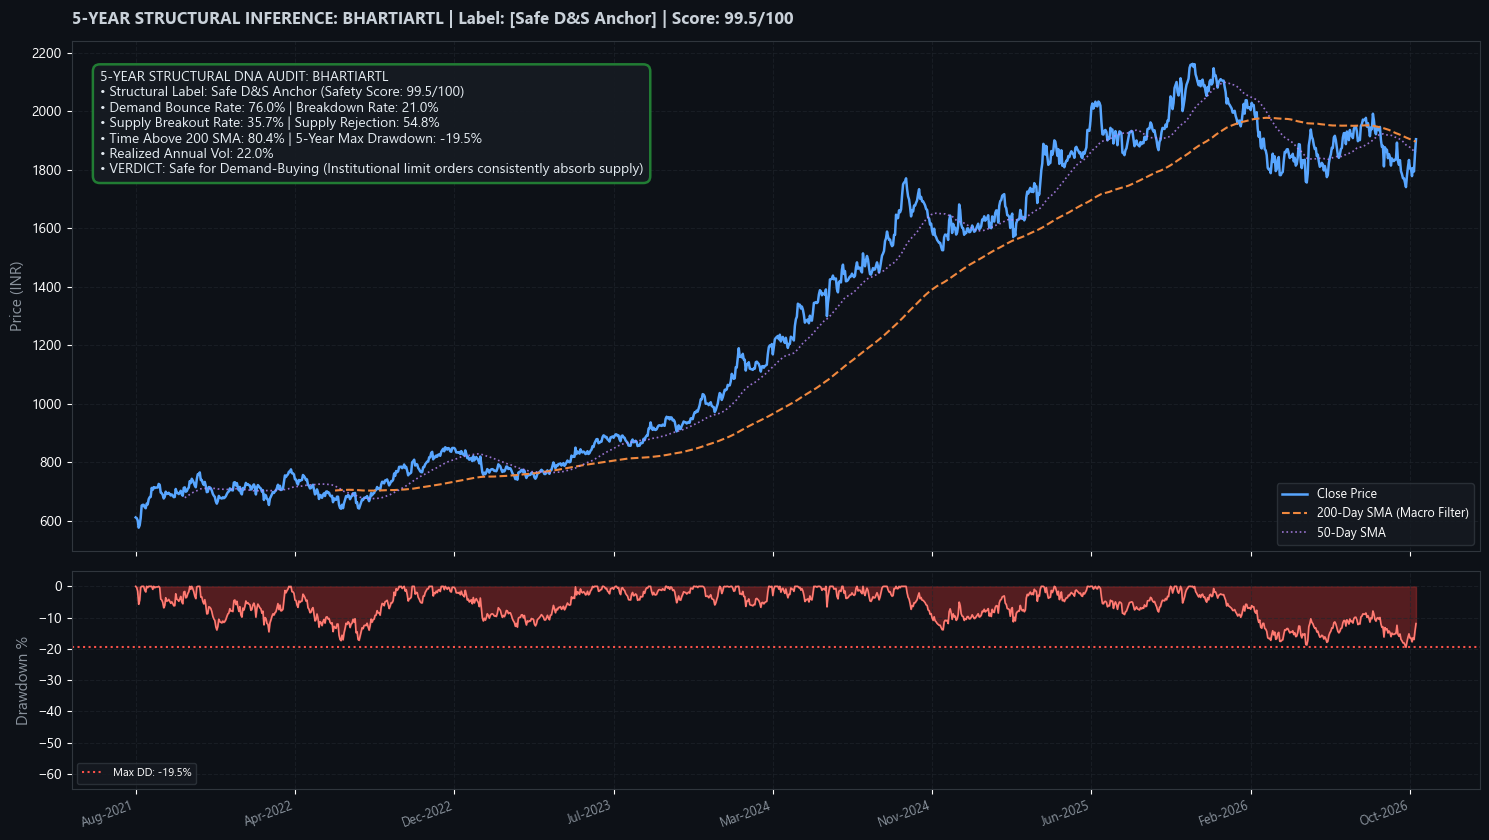

=== CASE STUDY 2: INSTITUTIONAL BANK ANCHOR (ICICIBANK) ===


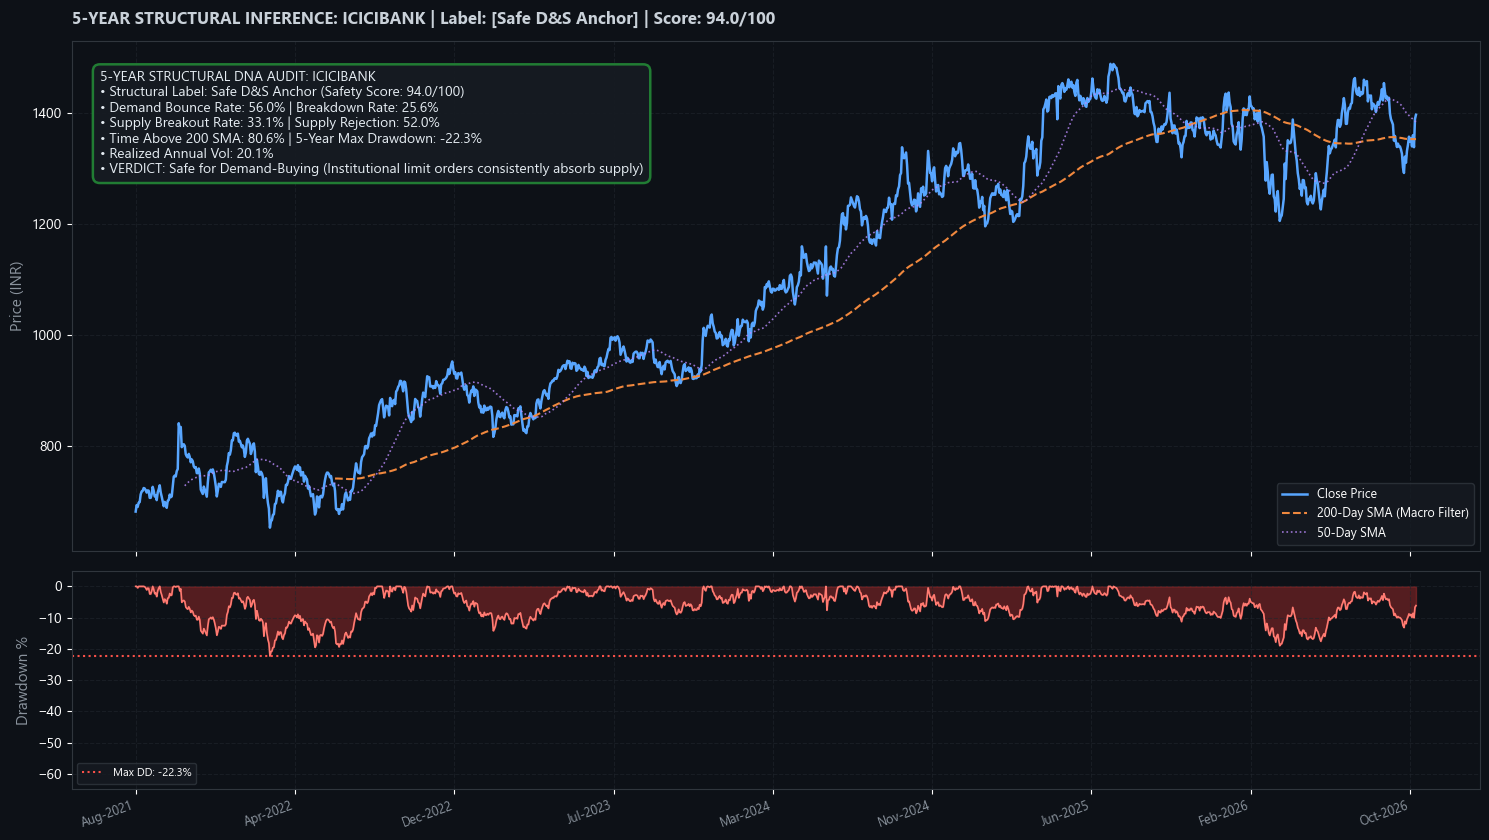

=== CASE STUDY 3: HIGH FALLING-ZONE RISK (ZEEL) ===


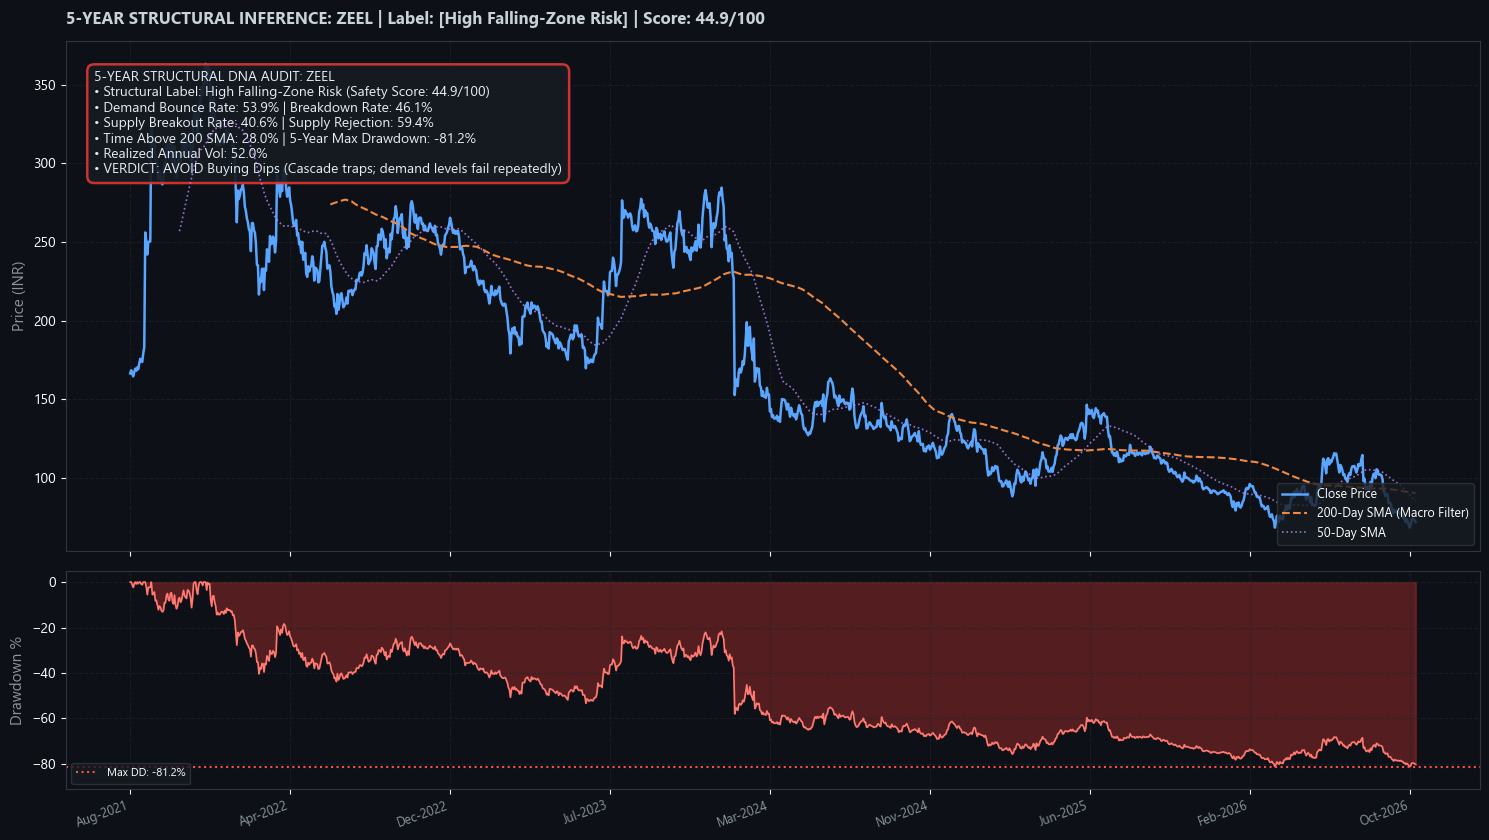

=== CASE STUDY 4: MEAN-REVERSION OSCILLATOR (TCS) ===


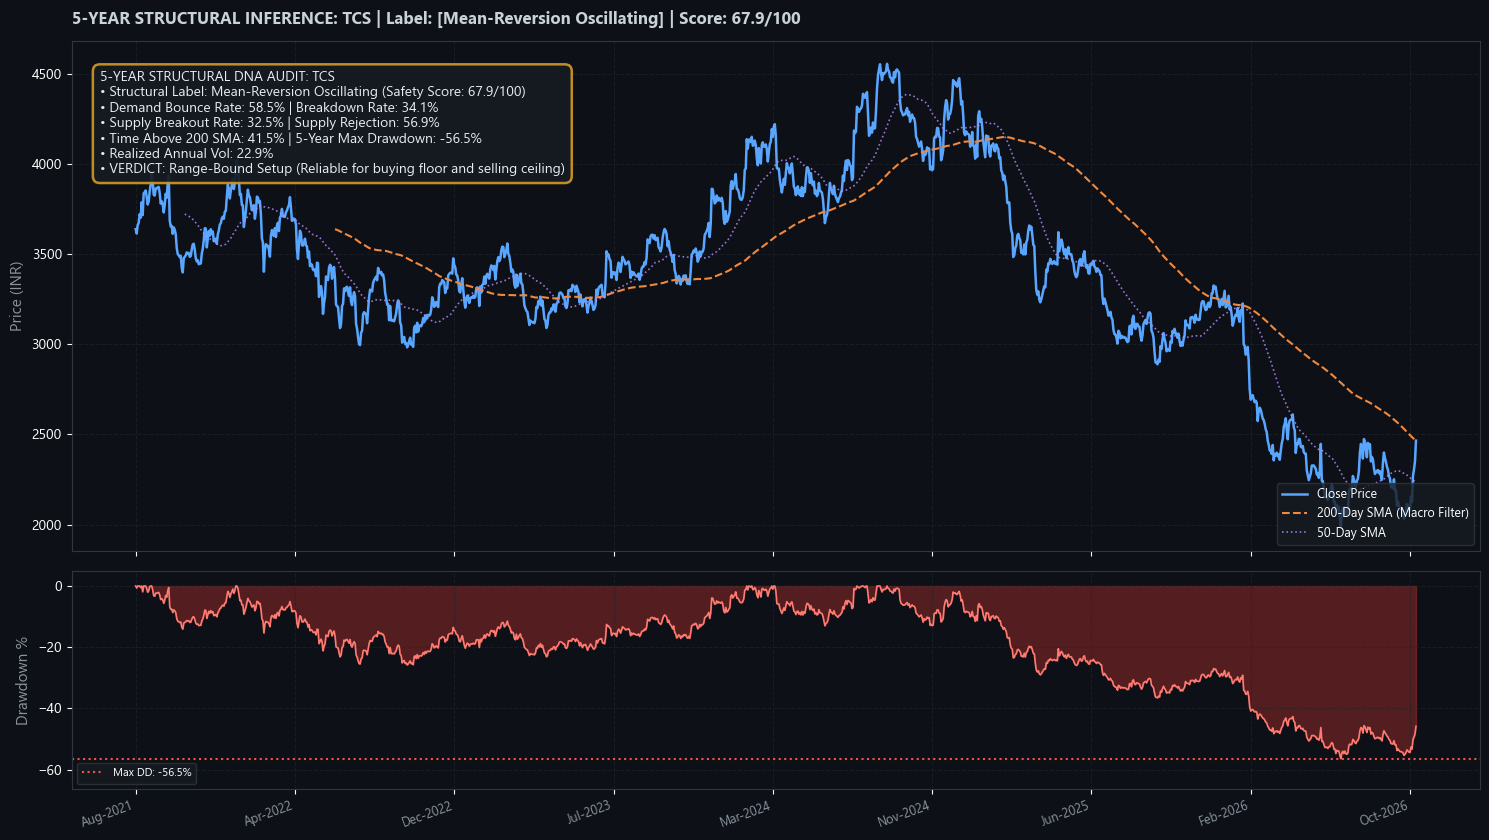

In [7]:
# Execute Step-by-Step Diagnostic Comparisons

# Case 1: Ultra-Safe D&S Anchor (BHARTIARTL - High support integrity, low drawdown)
print("=== CASE STUDY 1: PRIME SAFE ANCHOR (BHARTIARTL) ===")
plot_5y_structural_diagnostic('BHARTIARTL')

# Case 2: Institutional Safe Anchor (ICICIBANK - Consistent support bounces, >80% time above 200 SMA)
print("=== CASE STUDY 2: INSTITUTIONAL BANK ANCHOR (ICICIBANK) ===")
plot_5y_structural_diagnostic('ICICIBANK')

# Case 3: High Falling-Zone Risk Stock (ZEEL - Chronic breakdown of demand, deep -81% drawdown)
print("=== CASE STUDY 3: HIGH FALLING-ZONE RISK (ZEEL) ===")
plot_5y_structural_diagnostic('ZEEL')

# Case 4: Mean-Reversion Oscillator (TCS - Range-bound oscillation around macro SMA)
print("=== CASE STUDY 4: MEAN-REVERSION OSCILLATOR (TCS) ===")
plot_5y_structural_diagnostic('TCS')
